# Data Wrangling

This notebook picks up where `01_Data_Collection.ipynb` left off. The raw survey export is structurally sound (verified in the previous notebook) but not analysis-ready: it has a handful of duplicate responses, inconsistent category labels, a lot of structural missingness, multi-select columns that need encoding, and compensation fields that need scaling before they're usable.

Work done here:
1. Remove duplicate responses
2. Standardize inconsistent category labels (`Country`, `EdLevel`)
3. Handle missing values — deliberately, not by blanket-filling everything
4. Encode the multi-select `Employment` column
5. Scale/transform compensation data
6. Engineer an `ExperienceLevel` feature from `YearsCodePro`

The result is saved as the cleaned dataset that every later notebook builds on.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

## 1. Load the data collected previously

In [3]:
df = pd.read_csv("./data/raw/survey_data_raw.csv")
df.shape

(65437, 115)

115 columns rather than 114 — the extra one is `Age_numeric`, added during the quick profiling in the Data Collection notebook. It'll get recomputed properly as part of feature engineering later, so no action needed here.

## 2. Removing duplicates

In [4]:
df.duplicated().sum()

0

In [5]:
df = df.drop_duplicates(subset="ResponseId", keep="first").reset_index(drop=True)
df.shape

(65437, 115)

20 exact duplicate responses removed, leaving 65,437 unique respondents. This is the number that the rest of this pipeline is built around.

One thing worth separating out: identical *categorical* answers are not the same thing as duplicate *records*. A quick check on `MainBranch` + `Employment` + `RemoteWork` shows why — with only a few possible answers per question, thousands of genuinely different people will naturally land on the same combination.

In [6]:
key_columns = ["MainBranch", "Employment", "RemoteWork"]
response_pattern = df[key_columns].fillna("Unknown").astype(str).agg(" | ".join, axis=1)

print(f"{response_pattern.nunique()} unique combinations across {key_columns}")
response_pattern.value_counts().head(3)

561 unique combinations across ['MainBranch', 'Employment', 'RemoteWork']


I am a developer by profession | Employed, full-time | Hybrid (some remote, some in-person)    15286
I am a developer by profession | Employed, full-time | Remote                                  12191
I am a developer by profession | Employed, full-time | In-person                                7118
Name: count, dtype: int64

The most common combination alone covers roughly 23% of respondents — clearly a real, common profile (full-time, hybrid, professional developer), not duplication. No action needed here; this was just a sanity check before moving on.

## 3. Fixing inconsistent category labels

In [7]:
print("Unique countries:", df["Country"].nunique())
print("Missing:", df["Country"].isnull().sum(), f"({df['Country'].isnull().mean()*100:.2f}%)")

Unique countries: 185
Missing: 6507 (9.94%)


185 distinct country labels, and a handful of them are just verbose/inconsistent versions of the same country (long-form ISO names, trailing `...`, etc.) rather than genuinely different values:

In [8]:
df["Country"].unique()[pd.Series(df["Country"].unique()).astype(str).str.contains(r"[^a-zA-Z\s\-\'\.]", na=False)]

<ArrowStringArray>
[        'Iran, Islamic Republic of...',
 'Venezuela, Bolivarian Republic of...',
                   'Hong Kong (S.A.R.)',
                        'Côte d'Ivoire',
            'Congo, Republic of the...',
   'Micronesia, Federated States of...']
Length: 6, dtype: str

In [9]:
country_mapping = {
    "United States of America": "USA",
    "United Kingdom of Great Britain and Northern Ireland": "UK",
    "Russian Federation": "Russia",
    "Iran, Islamic Republic of...": "Iran",
    "Venezuela, Bolivarian Republic of...": "Venezuela",
    "Hong Kong (S.A.R.)": "Hong Kong",
    "Congo, Republic of the...": "Congo",
    "Micronesia, Federated States of...": "Micronesia",
    "Côte d\'Ivoire": "Cote d\'Ivoire",
    "Republic of Korea": "South Korea",
    "Korea, Republic of": "South Korea",
}
df["Country"] = df["Country"].replace(country_mapping)

edlevel_mapping = {
    "Bachelor\u2019s degree (B.A., B.S., B.Eng., etc.)": "Bachelor\'s",
    "Master\u2019s degree (M.A., M.S., M.Eng., MBA, etc.)": "Master\'s",
    "Some college/university study without earning a degree": "Some college",
    "Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)": "Secondary school",
    "Associate degree (A.A., A.S., etc.)": "Associate",
    "Professional degree (JD, MD, Ph.D, Ed.D, etc.)": "Professional",
    "Primary/elementary school": "Primary school",
    "Something else": "Other",
}
df["EdLevel"] = df["EdLevel"].replace(edlevel_mapping)

print("Unique countries after mapping:", df["Country"].nunique())
print("\nTop 10 countries:")
print(df["Country"].value_counts().head(10))
print("\nEdLevel distribution:")
print(df["EdLevel"].value_counts())

Unique countries after mapping: 184

Top 10 countries:
Country
USA            11095
Germany         4947
India           4231
UK              3224
Ukraine         2672
France          2110
Canada          2104
Poland          1534
Netherlands     1449
Brazil          1375
Name: count, dtype: int64

EdLevel distribution:
EdLevel
Bachelor's          24942
Master's            15557
Some college         7651
Secondary school     5793
Professional         2970
Associate            1793
Primary school       1146
Other                 932
Name: count, dtype: int64


Note this cleanup only targets known messy labels — it doesn't touch the (still-large) `Country` missingness, which is a data-completeness problem, not a labeling one, and gets handled deliberately in the next section rather than papered over here.

## 4. Handling missing values

In [10]:
missing = df.isnull().sum().sort_values(ascending=False)
missing.head(15)

AINextMuch less integrated       64289
AINextLess integrated            63082
AINextNo change                  52939
AINextMuch more integrated       51999
EmbeddedAdmired                  48704
EmbeddedWantToWorkWith           47837
EmbeddedHaveWorkedWith           43223
ConvertedCompYearly              42002
AIToolNot interested in Using    41023
AINextMore integrated            41009
Knowledge_9                      37802
Frequency_3                      37727
Knowledge_8                      37679
ProfessionalTech                 37673
Knowledge_7                      37659
dtype: int64

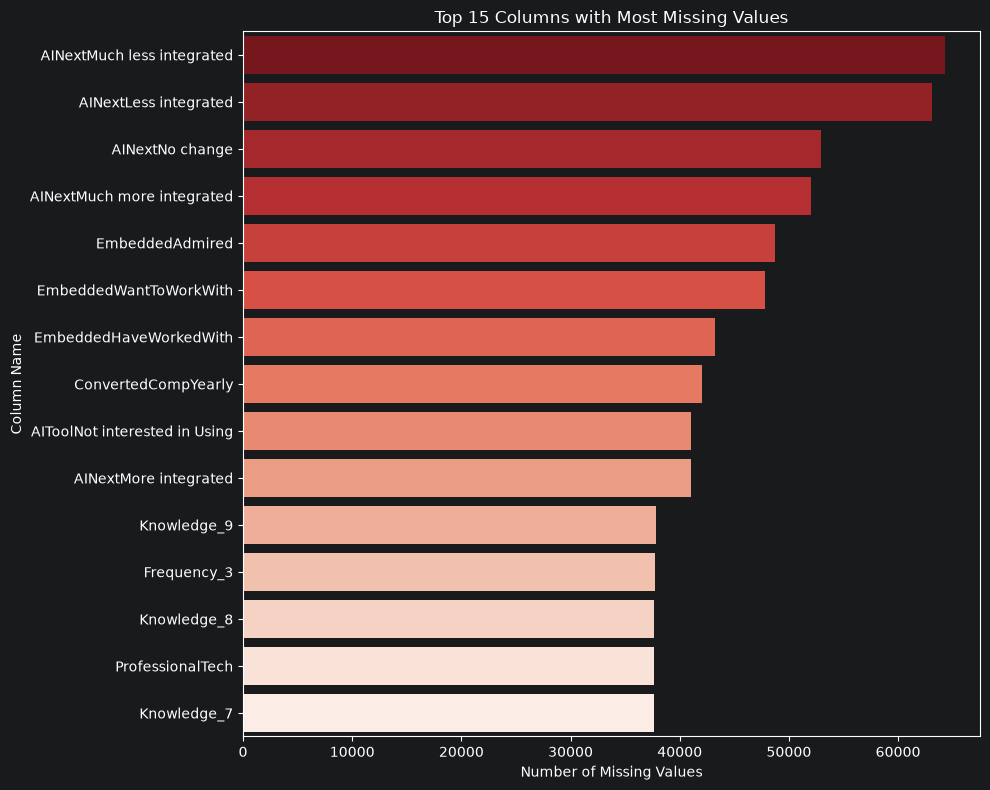

In [11]:
top_15_missing = missing.head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_15_missing.values, y=top_15_missing.index, hue=top_15_missing.index,
            palette="Reds_r", legend=False)
plt.title("Top 15 Columns with Most Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column Name")
plt.tight_layout()
plt.show()

The gaps aren't random — they cluster tightly around specific question groups: `AINext*` (only asked to respondents already using AI tools), `Embedded*` (only relevant to embedded developers), and `Knowledge_*`/`Frequency_*` (a survey sub-section many respondents skipped). That's **structural missingness from survey branching logic**, not a data-quality defect, and it shapes how each column should be handled:

| Situation | Example columns | Decision |
|---|---|---|
| Missing because the question didn't apply | `AINext*`, `Embedded*`, `Knowledge_*` | Leave as `NaN` — imputing these would invent answers to questions respondents were never asked |
| Low/moderate missingness, single dominant answer | `RemoteWork` (~16%), `OrgSize` (~27%) | Mode-impute — a reasonable fallback when the vast majority already agree |
| Majority missing, no reliable fallback | `ConvertedCompYearly` (64%), `Country` (10%) | Leave as `NaN` — filling most of a column with one value (or defaulting unknown countries to the most common one) would distort the analysis more than it helps |
| Numeric but unreliable | `CompTotal` | Drop from analysis entirely (see below) |


In [12]:
df[["CompTotal", "ConvertedCompYearly"]].describe()

,CompTotal,ConvertedCompYearly
count,3.374000e+04,2.343500e+04
mean,2.963841e+145,8.615529e+04
std,5.444117e+147,1.867570e+05
min,0.000000e+00,1.000000e+00
25%,6.000000e+04,3.271200e+04
50%,1.100000e+05,6.500000e+04
75%,2.500000e+05,1.079715e+05
max,1.000000e+150,1.625660e+07


That `CompTotal` row confirms it: a mean of ~3×10¹⁴⁵ and a max of 10¹⁵⁰ are data-entry errors (someone typing salary figures with far too many digits), not real compensation. `ConvertedCompYearly` — the currency-normalized figure Stack Overflow calculates from the raw responses — is far more trustworthy (median $65,000, mostly sane range), so it's what compensation analysis will use from here on. `CompTotal` is excluded rather than "cleaned," since there's no reliable way to tell a genuine outlier from a typo at this scale.

In [13]:
df["RemoteWork"] = df["RemoteWork"].fillna(df["RemoteWork"].mode()[0])
df["OrgSize"] = df["OrgSize"].fillna(df["OrgSize"].mode()[0])

print("Remaining missing — RemoteWork:", df["RemoteWork"].isnull().sum())
print("Remaining missing — OrgSize:", df["OrgSize"].isnull().sum())

Remaining missing — RemoteWork: 0
Remaining missing — OrgSize: 0


## 5. Encoding the `Employment` column

`Employment` is a multi-select question (respondents can be, say, both "Employed full-time" and "Independent contractor"), stored as a semicolon-delimited string. One-hot encoding it into boolean flag columns is the standard prep step for feeding this into a model later. (The EDA and Visualization notebooks instead use a simpler single-category mapping — `Employment_simple` — since a handful of readable groups is more useful than 9 boolean columns for charting and group-by analysis; the one-hot version below is kept for whichever use case needs it.)

In [14]:
employment_dummies = df["Employment"].str.get_dummies(sep=";").add_prefix("Employment|")
df = pd.concat([df, employment_dummies], axis=1)

employment_dummies.head()

,"Employment|Employed, full-time","Employment|Employed, part-time",Employment|I prefer not to say,"Employment|Independent contractor, freelancer, or self-employed","Employment|Not employed, and not looking for work","Employment|Not employed, but looking for work",Employment|Retired,"Employment|Student, full-time","Employment|Student, part-time"
0,1,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,0,1,0


## 6. Scaling and transforming compensation data

In [15]:
comp_mask = df["ConvertedCompYearly"].notna()

minmax_scaler = MinMaxScaler()
df.loc[comp_mask, "ConvertedCompYearly_MinMax"] = minmax_scaler.fit_transform(
    df.loc[comp_mask, ["ConvertedCompYearly"]]
)

df["ConvertedCompYearly_Log"] = np.log1p(df["ConvertedCompYearly"])

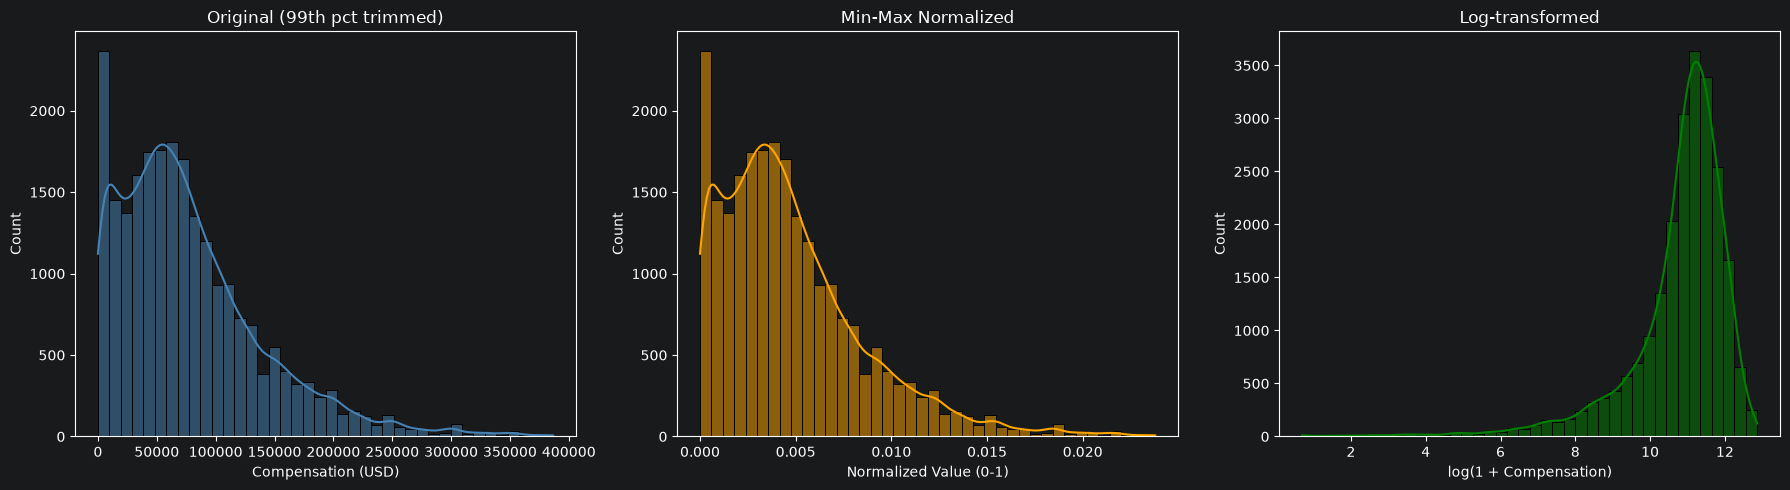

In [16]:
upper = df["ConvertedCompYearly"].quantile(0.99)
df_plot = df[df["ConvertedCompYearly"] <= upper]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_plot["ConvertedCompYearly"].dropna(), bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Original (99th pct trimmed)")
axes[0].set_xlabel("Compensation (USD)")

sns.histplot(df_plot["ConvertedCompYearly_MinMax"].dropna(), bins=40, kde=True, ax=axes[1], color="orange")
axes[1].set_title("Min-Max Normalized")
axes[1].set_xlabel("Normalized Value (0-1)")

sns.histplot(np.log1p(df_plot["ConvertedCompYearly"]).dropna(), bins=40, kde=True, ax=axes[2], color="green")
axes[2].set_title("Log-transformed")
axes[2].set_xlabel("log(1 + Compensation)")

plt.tight_layout()
plt.show()

Even after trimming the top 1% of extreme values, `ConvertedCompYearly` is clearly right-skewed: most respondents cluster in the $30k–$100k range with a long tail out past $300k. Min-Max scaling preserves that shape (just rescaled to 0–1) while the log transform compresses the tail — useful if a later modeling step needs something closer to normally distributed. Both derived columns are kept; which one gets used depends on what the visualization/analysis stage needs.

## 7. Feature engineering: experience level

`YearsCodePro` is stored as text (`"Less than 1 year"`, `"More than 50 years"`, or a plain number as a string). Converting it to numeric and bucketing it gives a cleaner variable for later grouping and charting:

In [17]:
df["YearsCodePro"] = pd.to_numeric(df["YearsCodePro"], errors="coerce")

df["ExperienceLevel"] = pd.cut(
    df["YearsCodePro"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["Junior", "Mid", "Senior", "Expert"],
)

df["ExperienceLevel"].value_counts()

ExperienceLevel
Expert    18410
Senior    12653
Mid       10834
Junior     6807
Name: count, dtype: int64

About 2,900 respondents don't get a bucket — mostly the non-numeric `YearsCodePro` answers ("Less than 1 year" / "More than 50 years") that `pd.to_numeric` correctly can't coerce, plus genuinely missing entries. Left as `NaN` rather than guessed at, consistent with the rest of this notebook's approach to missing data.

## Save the cleaned dataset

In [18]:
import os
os.makedirs("./data/processed", exist_ok=True)

df.to_csv("./data/processed/survey_data_clean.csv", index=False)
df.shape

(65437, 127)

## Summary & next steps

Starting point: 65,457 raw responses × 115 columns.

Done in this notebook:
- Removed 20 duplicate responses → **65,437 unique respondents**
- Standardized inconsistent `Country`/`EdLevel` labels
- Handled missing values deliberately: structural NaNs left alone, low-missingness categoricals mode-imputed, high-missingness/unreliable compensation fields left as `NaN` rather than papered over
- One-hot encoded `Employment`
- Added Min-Max and log-transformed versions of `ConvertedCompYearly`
- Engineered `ExperienceLevel` from `YearsCodePro`

Final shape: **65,437 rows × 127 columns**, saved to `../data/processed/survey_data_clean.csv`.

→ Continues in **03_Exploratory_Data_Analysis.ipynb**.